In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [4]:
df = pd.read_csv(r"C:\repo\heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 1025
Columns: 14


In [6]:
features = df.columns.drop("target").tolist()
print("Input features:", features)
print("Target variable: target (1 = heart disease, 0 = no disease)")
print(df["target"].value_counts())

Input features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Target variable: target (1 = heart disease, 0 = no disease)
target
1    526
0    499
Name: count, dtype: int64


In [7]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [9]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Duplicate rows: 723
Shape after removing duplicates: (302, 14)


In [10]:
X = df.drop("target", axis=1)
y = df["target"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (302, 13)
y shape: (302,)


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (211, 13)
Testing set: (91, 13)


In [12]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling done")

Feature scaling done


In [13]:
knn = KNeighborsClassifier(n_neighbors=5)

In [14]:
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)
print("Predictions:", y_pred[:10])

Predictions: [1 1 0 1 0 0 1 1 1 1]


In [15]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy (K=5): {accuracy*100:.2f}%")

Model Accuracy (K=5): 79.12%


In [16]:
k_values = [3, 5, 7, 9]
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_scaled, y_train)
    pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, pred)
    accuracies.append(acc)
    print(f"K = {k}: Accuracy = {acc*100:.2f}%")

K = 3: Accuracy = 75.82%
K = 5: Accuracy = 79.12%
K = 7: Accuracy = 80.22%
K = 9: Accuracy = 79.12%


   K  Accuracy (%)
0  3     75.824176
1  5     79.120879
2  7     80.219780
3  9     79.120879


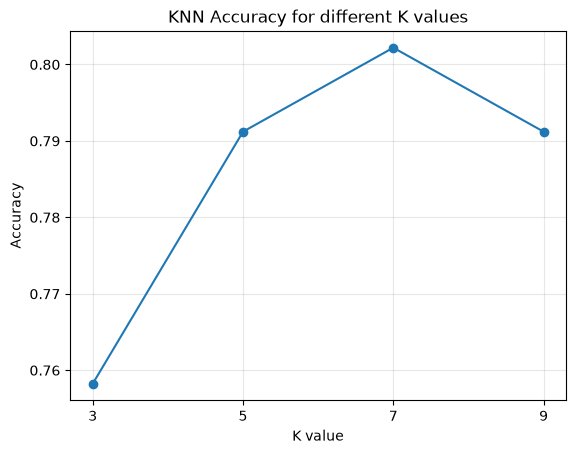

Best K = 7 with accuracy = 80.22%


In [17]:
results = pd.DataFrame({"K": k_values, "Accuracy (%)": [a*100 for a in accuracies]})
print(results)

plt.plot(k_values, accuracies, marker="o")
plt.xticks(k_values)
plt.xlabel("K value")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy for different K values")
plt.grid(alpha=0.3)
plt.show()

best_idx = np.argmax(accuracies)
print(f"Best K = {k_values[best_idx]} with accuracy = {accuracies[best_idx]*100:.2f}%")

## Conclusion
K = 3 gave 75.82%, K = 5 gave 79.12%, K = 7 gave 80.22% and K = 9 gave 79.12% accuracy.
**K = 7 performed best with 80.22% accuracy.**

## Conceptual Questions

**1. What is KNN?**
K-Nearest Neighbors is a simple supervised machine learning algorithm used for classification and regression. It is a lazy, instance-based learner: it stores the training data and makes decisions only at prediction time.

**2. How does KNN classify a new data point?**
It calculates the distance from the new point to all training points, selects the K nearest points, and assigns the class that appears most among those K neighbors (majority vote).

**3. What is the role of K in KNN?**
K is the number of neighbors that vote on the class of a new point. It controls how local or smooth the decision is. An odd K is usually chosen for binary problems to avoid ties.

**4. Why is feature scaling necessary for KNN?**
KNN depends on distance. Features with large ranges (like cholesterol) would dominate features with small ranges (like sex = 0/1). Scaling puts all features on the same scale so each one contributes fairly.

**5. What is Euclidean distance?**
It is the straight-line distance between two points:
d(p, q) = √[(p1 − q1)² + (p2 − q2)² + ... + (pn − qn)²]

**6. How can changing K affect model predictions?**
A small K is sensitive to noise and can overfit. A large K gives smoother predictions but can ignore local patterns and underfit. The best K balances both and is chosen by comparing accuracies.